# Calculate the metrics with a certain tolerance

In [4]:
import write_utils
import kpex_dev
import metrics
import pandas as pd
import numpy as np
import data_splits

feature_cols = data_splits.feature_cols
algorithms = data_splits.algorithms

In [2]:
import os
import pandas as pd
from typing import Optional

def collect_predictions_file(
    model_folder: str,
    filename_pattern: str = "all_predictions",
    excel: bool = False,
    sheet_name: Optional[str] = None
) -> pd.DataFrame:
    """
    For each file in `model_folder` matching filename_pattern:
      • if excel=True, looks for .xlsx and reads sheet_name
      • else   , looks for .csv
    Concatenates them into one DataFrame, adding a column
    'source_file' so you know which file each row came from.

    Returns
    -------
    combined : pd.DataFrame
    """
    collected = []
    for fname in os.listdir(model_folder):
        if not fname.startswith(filename_pattern):
            continue

        path = os.path.join(model_folder, fname)
        if excel:
            if not fname.lower().endswith(".xlsx"):
                continue
            df = pd.read_excel(path, sheet_name=sheet_name or 0)
        else:
            if not fname.lower().endswith(".csv"):
                continue
            df = pd.read_csv(path)

        df = df.copy()
        df['source_file'] = fname
        collected.append(df)

    if not collected:
        raise FileNotFoundError(f"No files matching '{filename_pattern}' in {model_folder}")

    combined = pd.concat(collected, ignore_index=True)
    return combined


## Scheme 1: Each algorithm being a separate class

### For Random Forest

In [3]:
def get_true_fastest_algorithm(row, algorithms):
    times = {alg: row[alg] for alg in algorithms}
    return min(times, key=times.get)

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def plot_algorithm_confusion_matrix(
    df,
    algorithms,
    normalize=None,
    figsize=(8, 8),
    cmap="Blues"
):
    """
    Plot confusion matrix for algorithm selection.

    Ground truth: fastest algorithm (min runtime)
    Prediction: df['predicted']

    Parameters
    ----------
    df : pandas.DataFrame
        Must contain algorithm runtime columns and 'predicted'
    algorithms : list[str]
        List of algorithm names
    normalize : {'true', 'pred', 'all', None}
        Normalization mode (sklearn-style)
    """

    # ----- True labels -----
    y_true = df.apply(
        lambda r: get_true_fastest_algorithm(r, algorithms),
        axis=1
    )

    # ----- Predicted labels -----
    y_pred = df["predicted"]

    # ----- Confusion matrix -----
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=algorithms,
        # normalize=normalize
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=algorithms
    )

    fig, ax = plt.subplots(figsize=figsize)
    disp.plot(ax=ax, cmap=cmap, colorbar=True)

    title = "Algorithm Confusion Matrix"
    if normalize:
        title += f" (normalized={normalize})"
    ax.set_title(title)

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


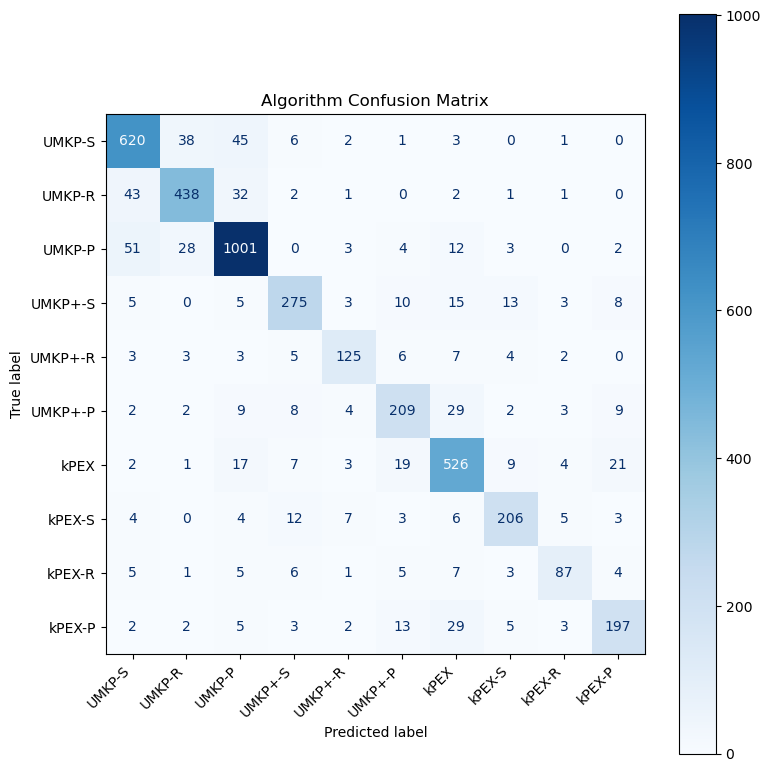

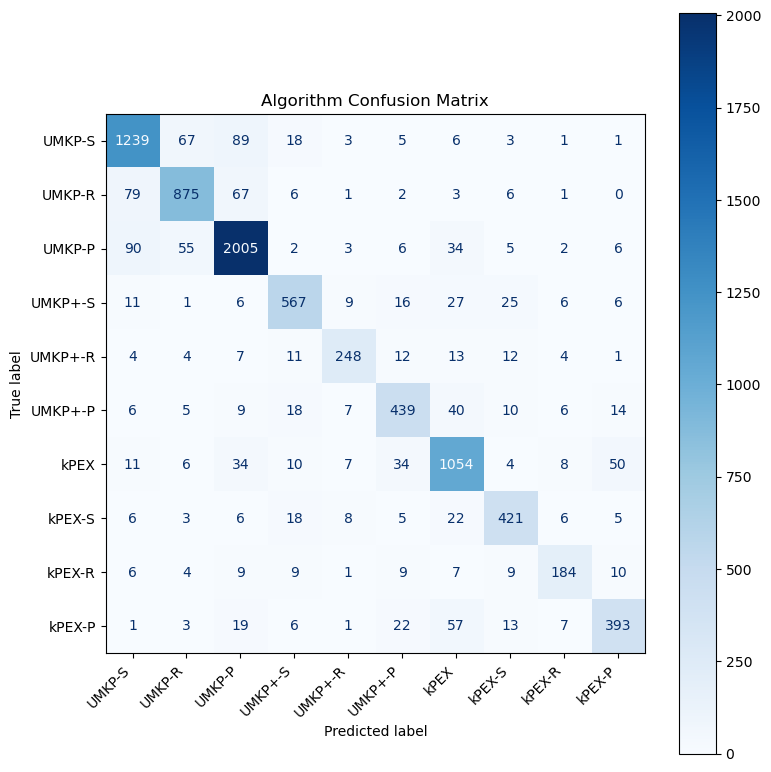

In [60]:
master_for_XGB_expand_and_split_sc1 = collect_predictions_file(
    model_folder="../outputs/XGB_results/tie_tol/0/expand_and_split", 
    filename_pattern="all_predictions_inference_entire_data_without_holdout_strat_y",
)
plot_algorithm_confusion_matrix(master_for_XGB_expand_and_split, algorithms)
plot_algorithm_confusion_matrix(master_for_XGB_expand_and_split_sc1, algorithms)
#confusion_matrix_norm_pred_tie_tol_0


In [51]:

master_for_RF_expand_and_split = collect_predictions_file(
    model_folder="../outputs/RF_results/hier5/strat_y_K",
    filename_pattern="all_predictions_inference_entire_data_without_holdout",
)


#### Tolerance = 0

In [52]:
classification_metrics = metrics.evaluate_with_tolerance(master_for_RF_expand_and_split, algorithms)
time_metrics = metrics.evaluate_time_metrics_with_tol(master_for_RF_expand_and_split, algorithms, tol=0.0)

# Helper function: Write the displayed metrics to an excel file. Change number of sheet in accord with the experiment number
kpex_dev.write_metrics_to_excel_file(classification_metrics, time_metrics, 
                                    "../outputs/RF_results/hier5/strat_y_K/model_performance_for_evaluation_tol_entire_data.xlsx", 
                                    'entire_dataset_y_tol_0')

Accuracy (±0.0% ties counted as correct): 56.52%

Precision by Algorithm:
  UMKP-S: 49.89% (912 preds)
  UMKP-R: 48.86% (440 preds)
  UMKP-P: 66.08% (967 preds)
  UMKP+-S: 65.25% (259 preds)
  UMKP+-R: 58.57% (140 preds)
  UMKP+-P: 69.67% (122 preds)
  kPEX: 50.84% (1011 preds)
  kPEX-S: 54.24% (295 preds)
  kPEX-R: 64.37% (87 preds)
  kPEX-P: 70.73% (123 preds)

Average Precision (AP) by Algorithm:
  UMKP-S: 0.6268
  UMKP-R: 0.4924
  UMKP-P: 0.7109
  UMKP+-S: 0.6577
  UMKP+-R: 0.5427
  UMKP+-P: 0.6423
  kPEX: 0.7067
  kPEX-S: 0.6651
  kPEX-R: 0.5399
  kPEX-P: 0.5548

Recall by Algorithm:
  UMKP-S: 63.55% (455/716)
  UMKP-R: 41.35% (215/520)
  UMKP-P: 57.88% (639/1104)
  UMKP+-S: 50.45% (170/337)
  UMKP+-R: 51.90% (82/158)
  UMKP+-P: 30.94% (86/278)
  kPEX: 84.15% (515/612)
  kPEX-S: 63.75% (160/251)
  kPEX-R: 45.60% (57/125)
  kPEX-P: 33.59% (88/262)
Time Metrics:
  Total Predicted Time = 233127.59
  Total Optimal Time   = 111146.05
  Time Ratio (pred/opt)= 2.097
  Avg Overhead/case (

#### Tolerance = 10%

In [53]:
classification_metrics = metrics.evaluate_with_tolerance(master_for_RF_expand_and_split, algorithms, tol=0.10)
time_metrics = metrics.evaluate_time_metrics_with_tol(master_for_RF_expand_and_split, algorithms, tol=0.10)

# Helper function: Write the displayed metrics to an excel file. Change number of sheet in accord with the experiment number
kpex_dev.write_metrics_to_excel_file(classification_metrics, time_metrics, 
                                    "../outputs/RF_results/hier5/strat_y_K/model_performance_for_evaluation_tol_entire_data.xlsx", 
                                    'entire_dataset_y_tol_10')

Accuracy (±10.0% ties counted as correct): 76.08%

Precision by Algorithm:
  UMKP-S: 74.12% (912 preds)
  UMKP-R: 73.64% (440 preds)
  UMKP-P: 85.21% (967 preds)
  UMKP+-S: 76.83% (259 preds)
  UMKP+-R: 70.71% (140 preds)
  UMKP+-P: 77.87% (122 preds)
  kPEX: 69.04% (1011 preds)
  kPEX-S: 75.93% (295 preds)
  kPEX-R: 80.46% (87 preds)
  kPEX-P: 85.37% (123 preds)

Average Precision (AP) by Algorithm:
  UMKP-S: 0.7874
  UMKP-R: 0.6990
  UMKP-P: 0.8599
  UMKP+-S: 0.6371
  UMKP+-R: 0.4401
  UMKP+-P: 0.6002
  kPEX: 0.7362
  kPEX-S: 0.5908
  kPEX-R: 0.4586
  kPEX-P: 0.5985

Recall by Algorithm:
  UMKP-S: 88.37% (1276/1444)
  UMKP-R: 84.41% (931/1103)
  UMKP-P: 81.68% (1485/1818)
  UMKP+-S: 72.30% (543/751)
  UMKP+-R: 71.51% (364/509)
  UMKP+-P: 75.45% (627/831)
  kPEX: 88.36% (1017/1151)
  kPEX-S: 75.27% (551/732)
  kPEX-R: 73.73% (376/510)
  kPEX-P: 78.11% (753/964)
Time Metrics:
  Total Predicted Time = 232835.66
  Total Optimal Time   = 111146.05
  Time Ratio (pred/opt)= 2.095
  Avg Over

#### Tolerance = 20%

In [54]:
classification_metrics = metrics.evaluate_with_tolerance(master_for_RF_expand_and_split, algorithms,tol=0.20)
time_metrics = metrics.evaluate_time_metrics_with_tol(master_for_RF_expand_and_split, algorithms, tol=0.20)

# Helper function: Write the displayed metrics to an excel file. Change number of sheet in accord with the experiment number
kpex_dev.write_metrics_to_excel_file(classification_metrics, time_metrics, 
                                    "../outputs/RF_results/hier5/strat_y_K/model_performance_for_evaluation_tol_entire_data.xlsx", 
                                    'entire_dataset_y_tol_20')

Accuracy (±20.0% ties counted as correct): 84.37%

Precision by Algorithm:
  UMKP-S: 82.68% (912 preds)
  UMKP-R: 82.95% (440 preds)
  UMKP-P: 90.59% (967 preds)
  UMKP+-S: 83.01% (259 preds)
  UMKP+-R: 75.71% (140 preds)
  UMKP+-P: 81.97% (122 preds)
  kPEX: 82.10% (1011 preds)
  kPEX-S: 83.73% (295 preds)
  kPEX-R: 86.21% (87 preds)
  kPEX-P: 86.99% (123 preds)

Average Precision (AP) by Algorithm:
  UMKP-S: 0.8433
  UMKP-R: 0.7871
  UMKP-P: 0.9075
  UMKP+-S: 0.6633
  UMKP+-R: 0.4759
  UMKP+-P: 0.6646
  kPEX: 0.7942
  kPEX-S: 0.6379
  kPEX-R: 0.5264
  kPEX-P: 0.6989

Recall by Algorithm:
  UMKP-S: 92.92% (1574/1694)
  UMKP-R: 91.55% (1214/1326)
  UMKP-P: 87.91% (1803/2051)
  UMKP+-S: 84.26% (830/985)
  UMKP+-R: 81.92% (589/719)
  UMKP+-P: 86.91% (1009/1161)
  kPEX: 91.55% (1366/1492)
  kPEX-S: 83.97% (817/973)
  kPEX-R: 84.20% (650/772)
  kPEX-P: 89.76% (1201/1338)
Time Metrics:
  Total Predicted Time = 232475.60
  Total Optimal Time   = 111146.05
  Time Ratio (pred/opt)= 2.092
  Avg

#### Tolerance = 50%

In [55]:
classification_metrics = metrics.evaluate_with_tolerance(master_for_RF_expand_and_split, algorithms, tol=0.50)
time_metrics = metrics.evaluate_time_metrics_with_tol(master_for_RF_expand_and_split, algorithms, tol=0.50)

# Helper function: Write the displayed metrics to an excel file. Change number of sheet in accord with the experiment number
kpex_dev.write_metrics_to_excel_file(classification_metrics, time_metrics, 
                                    "../outputs/RF_results/hier5/strat_y_K/model_performance_for_evaluation_tol_entire_data.xlsx", 
                                    'entire_dataset_y_tol_50')

Accuracy (±50.0% ties counted as correct): 91.32%

Precision by Algorithm:
  UMKP-S: 90.35% (912 preds)
  UMKP-R: 90.23% (440 preds)
  UMKP-P: 94.11% (967 preds)
  UMKP+-S: 88.42% (259 preds)
  UMKP+-R: 82.86% (140 preds)
  UMKP+-P: 89.34% (122 preds)
  kPEX: 90.90% (1011 preds)
  kPEX-S: 93.90% (295 preds)
  kPEX-R: 96.55% (87 preds)
  kPEX-P: 91.87% (123 preds)

Average Precision (AP) by Algorithm:
  UMKP-S: 0.8933
  UMKP-R: 0.8484
  UMKP-P: 0.9338
  UMKP+-S: 0.7142
  UMKP+-R: 0.5580
  UMKP+-P: 0.7350
  kPEX: 0.8369
  kPEX-S: 0.7039
  kPEX-R: 0.6409
  kPEX-P: 0.8176

Recall by Algorithm:
  UMKP-S: 95.59% (1927/2016)
  UMKP-R: 96.07% (1516/1578)
  UMKP-P: 94.39% (2254/2388)
  UMKP+-S: 91.62% (1399/1527)
  UMKP+-R: 90.40% (1055/1167)
  UMKP+-P: 93.49% (1667/1783)
  kPEX: 94.16% (1869/1985)
  kPEX-S: 90.24% (1331/1475)
  kPEX-R: 90.61% (1139/1257)
  kPEX-P: 94.24% (1815/1926)
Time Metrics:
  Total Predicted Time = 229179.84
  Total Optimal Time   = 111146.05
  Time Ratio (pred/opt)= 2.0

In [56]:
# Consolidate all metrics

write_utils.consolidate_experiments("../outputs/RF_results/hier5/strat_y_K/model_performance_for_evaluation_tol_entire_data.xlsx", 
    prefix="entire_dataset_",
    master_name="entire_dataset_tolerences"
)



✅ Consolidated 4 sheets into 'entire_dataset_tolerences' in ../outputs/RF_results/hier5/strat_y_K/model_performance_for_evaluation_tol_entire_data.xlsx


### For XGBoost

In [58]:

master_for_XGB_expand_and_split = collect_predictions_file(
    model_folder="../outputs/XGB_results/hier5/strat_y", 
    filename_pattern="all_predictions_inference_entire_data_without_holdout",
)


#### Tolerance = 0

In [46]:
classification_metrics = metrics.evaluate_with_tolerance(master_for_XGB_expand_and_split, algorithms)
time_metrics = metrics.evaluate_time_metrics_with_tol(master_for_XGB_expand_and_split, algorithms, tol=0.0)

# Helper function: Write the displayed metrics to an excel file. Change number of sheet in accord with the experiment number
kpex_dev.write_metrics_to_excel_file(classification_metrics, time_metrics, 
                                    "../outputs/XGB_results/hier5/strat_y/model_performance_for_evaluation_tol_entire_data.xlsx", 
                                    'entire_dataset_y_tol_0')

Accuracy (±0.0% ties counted as correct): 84.62%

Precision by Algorithm:
  UMKP-S: 84.12% (737 preds)
  UMKP-R: 85.38% (513 preds)
  UMKP-P: 88.90% (1126 preds)
  UMKP+-S: 84.88% (324 preds)
  UMKP+-R: 82.78% (151 preds)
  UMKP+-P: 77.41% (270 preds)
  kPEX: 82.86% (636 preds)
  kPEX-S: 83.74% (246 preds)
  kPEX-R: 79.82% (109 preds)
  kPEX-P: 81.15% (244 preds)

Average Precision (AP) by Algorithm:
  UMKP-S: 0.9034
  UMKP-R: 0.8944
  UMKP-P: 0.9521
  UMKP+-S: 0.8815
  UMKP+-R: 0.8237
  UMKP+-P: 0.7967
  kPEX: 0.9092
  kPEX-S: 0.8758
  kPEX-R: 0.7807
  kPEX-P: 0.8216

Recall by Algorithm:
  UMKP-S: 86.59% (620/716)
  UMKP-R: 84.23% (438/520)
  UMKP-P: 90.67% (1001/1104)
  UMKP+-S: 81.60% (275/337)
  UMKP+-R: 79.11% (125/158)
  UMKP+-P: 75.54% (210/278)
  kPEX: 86.60% (530/612)
  kPEX-S: 82.47% (207/251)
  kPEX-R: 70.40% (88/125)
  kPEX-P: 75.57% (198/262)
Time Metrics:
  Total Predicted Time = 154483.17
  Total Optimal Time   = 111146.05
  Time Ratio (pred/opt)= 1.390
  Avg Overhead/c

#### Tolerance = 10%

In [47]:
classification_metrics = metrics.evaluate_with_tolerance(master_for_XGB_expand_and_split, algorithms, tol=0.10)
time_metrics = metrics.evaluate_time_metrics_with_tol(master_for_XGB_expand_and_split, algorithms, tol=0.10)

# Helper function: Write the displayed metrics to an excel file. Change number of sheet in accord with the experiment number
kpex_dev.write_metrics_to_excel_file(classification_metrics, time_metrics, 
                                    "../outputs/XGB_results/hier5/strat_y/model_performance_for_evaluation_tol_entire_data.xlsx", 
                                    'entire_dataset_y_tol_10')

Accuracy (±10.0% ties counted as correct): 92.36%

Precision by Algorithm:
  UMKP-S: 93.08% (737 preds)
  UMKP-R: 94.54% (513 preds)
  UMKP-P: 94.14% (1126 preds)
  UMKP+-S: 92.90% (324 preds)
  UMKP+-R: 87.42% (151 preds)
  UMKP+-P: 86.67% (270 preds)
  kPEX: 91.98% (636 preds)
  kPEX-S: 89.84% (246 preds)
  kPEX-R: 86.24% (109 preds)
  kPEX-P: 92.21% (244 preds)

Average Precision (AP) by Algorithm:
  UMKP-S: 0.8246
  UMKP-R: 0.8170
  UMKP-P: 0.8956
  UMKP+-S: 0.7137
  UMKP+-R: 0.5167
  UMKP+-P: 0.6506
  kPEX: 0.7893
  kPEX-S: 0.6111
  kPEX-R: 0.4475
  kPEX-P: 0.6154

Recall by Algorithm:
  UMKP-S: 96.05% (1387/1444)
  UMKP-R: 96.28% (1062/1103)
  UMKP-P: 96.64% (1757/1818)
  UMKP+-S: 90.41% (679/751)
  UMKP+-R: 90.77% (462/509)
  UMKP+-P: 91.70% (762/831)
  kPEX: 92.27% (1062/1151)
  kPEX-S: 90.03% (659/732)
  kPEX-R: 87.45% (446/510)
  kPEX-P: 92.01% (887/964)
Time Metrics:
  Total Predicted Time = 154326.14
  Total Optimal Time   = 111146.05
  Time Ratio (pred/opt)= 1.388
  Avg Ov

#### Tolerance = 20%

In [48]:
classification_metrics = metrics.evaluate_with_tolerance(master_for_XGB_expand_and_split, algorithms,tol=0.20)
time_metrics = metrics.evaluate_time_metrics_with_tol(master_for_XGB_expand_and_split, algorithms, tol=0.20)

# Helper function: Write the displayed metrics to an excel file. Change number of sheet in accord with the experiment number
kpex_dev.write_metrics_to_excel_file(classification_metrics, time_metrics, 
                                    "../outputs/XGB_results/hier5/strat_y/model_performance_for_evaluation_tol_entire_data.xlsx", 
                                    'entire_dataset_y_tol_20')

Accuracy (±20.0% ties counted as correct): 95.16%

Precision by Algorithm:
  UMKP-S: 94.71% (737 preds)
  UMKP-R: 97.08% (513 preds)
  UMKP-P: 96.27% (1126 preds)
  UMKP+-S: 94.14% (324 preds)
  UMKP+-R: 91.39% (151 preds)
  UMKP+-P: 94.07% (270 preds)
  kPEX: 96.07% (636 preds)
  kPEX-S: 93.50% (246 preds)
  kPEX-R: 87.16% (109 preds)
  kPEX-P: 95.08% (244 preds)

Average Precision (AP) by Algorithm:
  UMKP-S: 0.8435
  UMKP-R: 0.8403
  UMKP-P: 0.9097
  UMKP+-S: 0.7056
  UMKP+-R: 0.5443
  UMKP+-P: 0.7222
  kPEX: 0.8092
  kPEX-S: 0.6540
  kPEX-R: 0.4782
  kPEX-P: 0.6689

Recall by Algorithm:
  UMKP-S: 97.87% (1658/1694)
  UMKP-R: 97.36% (1291/1326)
  UMKP-P: 97.71% (2004/2051)
  UMKP+-S: 94.21% (928/985)
  UMKP+-R: 94.44% (679/719)
  UMKP+-P: 94.83% (1101/1161)
  kPEX: 95.64% (1427/1492)
  kPEX-S: 93.01% (905/973)
  kPEX-R: 93.65% (723/772)
  kPEX-P: 95.67% (1280/1338)
Time Metrics:
  Total Predicted Time = 154182.30
  Total Optimal Time   = 111146.05
  Time Ratio (pred/opt)= 1.387
  Av

#### Tolerance = 50%

In [49]:
classification_metrics = metrics.evaluate_with_tolerance(master_for_XGB_expand_and_split, algorithms, tol=0.50)
time_metrics = metrics.evaluate_time_metrics_with_tol(master_for_XGB_expand_and_split, algorithms, tol=0.50)

# Helper function: Write the displayed metrics to an excel file. Change number of sheet in accord with the experiment number
kpex_dev.write_metrics_to_excel_file(classification_metrics, time_metrics, 
                                    "../outputs/XGB_results/hier5/strat_y/model_performance_for_evaluation_tol_entire_data.xlsx", 
                                    'entire_dataset_y_tol_50')

Accuracy (±50.0% ties counted as correct): 97.45%

Precision by Algorithm:
  UMKP-S: 96.74% (737 preds)
  UMKP-R: 99.03% (513 preds)
  UMKP-P: 97.34% (1126 preds)
  UMKP+-S: 96.91% (324 preds)
  UMKP+-R: 94.04% (151 preds)
  UMKP+-P: 97.41% (270 preds)
  kPEX: 98.74% (636 preds)
  kPEX-S: 95.53% (246 preds)
  kPEX-R: 95.41% (109 preds)
  kPEX-P: 99.18% (244 preds)

Average Precision (AP) by Algorithm:
  UMKP-S: 0.8696
  UMKP-R: 0.8603
  UMKP-P: 0.9219
  UMKP+-S: 0.7487
  UMKP+-R: 0.6075
  UMKP+-P: 0.7798
  kPEX: 0.8419
  kPEX-S: 0.7194
  kPEX-R: 0.5960
  kPEX-P: 0.7828

Recall by Algorithm:
  UMKP-S: 98.71% (1990/2016)
  UMKP-R: 98.54% (1555/1578)
  UMKP-P: 98.91% (2362/2388)
  UMKP+-S: 97.71% (1492/1527)
  UMKP+-R: 97.77% (1141/1167)
  UMKP+-P: 97.98% (1747/1783)
  kPEX: 97.68% (1939/1985)
  kPEX-S: 96.88% (1429/1475)
  kPEX-R: 96.98% (1219/1257)
  kPEX-P: 97.72% (1882/1926)
Time Metrics:
  Total Predicted Time = 153342.31
  Total Optimal Time   = 111146.05
  Time Ratio (pred/opt)= 1.

In [50]:
# Consolidate all metrics

write_utils.consolidate_experiments("../outputs/XGB_results/hier5/strat_y/model_performance_for_evaluation_tol_entire_data.xlsx", 
    prefix="entire_dataset_",
    master_name="entire_dataset_tolerences"
)



✅ Consolidated 4 sheets into 'entire_dataset_tolerences' in ../outputs/XGB_results/hier5/strat_y/model_performance_for_evaluation_tol_entire_data.xlsx
